<a href="https://colab.research.google.com/github/omar-geberi/ML-QC/blob/main/Lab3_CMAI_QML_Resolved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install qiskit==1.4.2
!pip install qiskit_aer
!pip install qiskit_machine_learning
!pip install qiskit_algorithms
!pip install matplotlib
!pip install pylatexenc
!pip install scipy
!pip install -U scikit-learn

!git clone https://github.com/IsaVia777/atelier_qml.git

  Using cached qiskit-1.4.2-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (12 kB)
Using cached qiskit-1.4.2-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (6.8 MB)
  Attempting uninstall: qiskit
    Found existing installation: qiskit 2.6.2
    Uninstalling qiskit-2.6.2:
      Successfully uninstalled qiskit-2.6.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
qiskit-machine-learning 0.9.1 requires qiskit>=2.0, but you have qiskit 1.4.2 which is incompatible.
  Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl (9.5 MB)
  Attempting uninstall: qiskit
    Found existing installation: qiskit 1.4.2
    Uninstalling qiskit-1.4.2:
      Successfully uninstalled qiskit-1.4.2
fatal: destination path 'atelier_qml' already exists and is not an empty

# Lab 3: Classification

**Objectives**
- Classify data in higher dimensional space using 1 qubit
- Measurement along $X$,$Y$,$Z$ axis

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit
from qiskit_aer import Aer

SEED = 8398

In [4]:
import sys
sys.path.insert(0, '/content/atelier_qml')

from utils import *

In [5]:
qasm_sim = Aer.get_backend('qasm_simulator')
sv_sim = Aer.get_backend('statevector_simulator')

### 1D linearly separable dataset

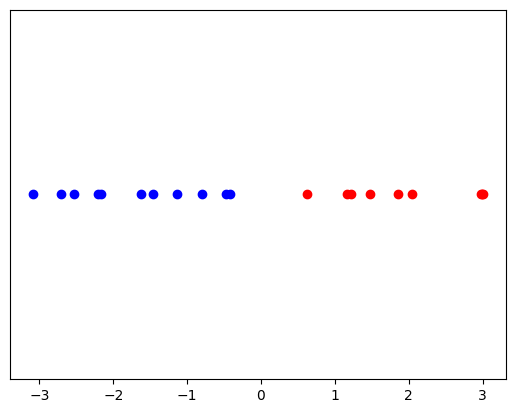

In [6]:
x,y,x0,x1 = get_seperable_data()
nb_features = 1

# Let's see what our dataset look like. Label 0 in blue, label 1 in red
plt.yticks([])
plt.scatter(x0, [0]*len(x0), color='blue')
plt.scatter(x1, [0]*len(x1), color='red')

Embedding datapoints in the rotation angle about the X-axis

In [7]:
def angle_embedding(x_params,nb_features):

    """
    Qubit - or rotation - encoding in RX gates.

    :param x_params: List of parameters to embed.
    :param nb_features: The number of features of the feature vector.
    :return: The quantum circuit with the embedding layer.
    """

    qc = QuantumCircuit(nb_features)

    for i in range(nb_features):
        qc.rx(x_params[i], i)

    return qc


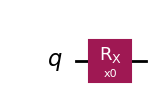

In [8]:
# Create a list of `Parameter`. Since the data points have only one feature
# there will be only one parameter in this list.
x_params = [Parameter(f'x{str(i)}') for i in range(nb_features)]

# Create the parametrized embedding layer
qc = angle_embedding(x_params, nb_features)

qc.draw('mpl')

Encoding for datapoint [-2.16188971]:


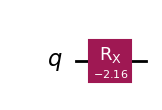

In [9]:
emb_circuit = qc.assign_parameters(x[0])

print(f'Encoding for datapoint {x[0]}:')
emb_circuit.draw('mpl')

### Using angle embedding to map this data into a quantum feature space.

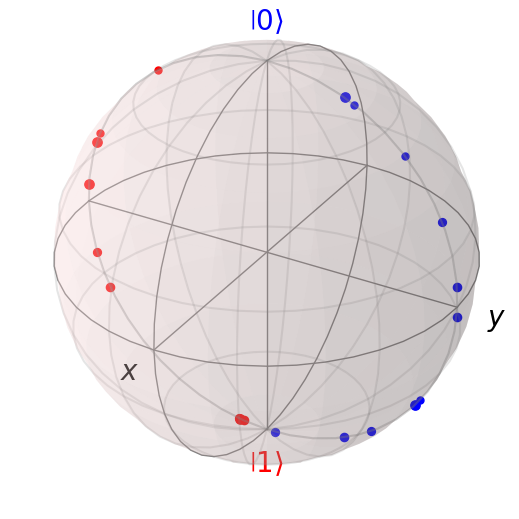

In [10]:
statevectors0 = get_statevector(qc, x0, x_params, sv_sim)
statevectors1 = get_statevector(qc, x1, x_params, sv_sim)
plot_bloch_visualization([statevectors0, statevectors1], ['b', 'r'])

## Implementation of the classification algorithm
![lab3.png](https://github.com/IsaVia777/atelier_qml/blob/main/lab3.png?raw=1)

In [11]:
shots = 1024


def get_measurement_outcomes(data, emb_circuit, rot_circuit=None):
    """
    Run the circuit of the binary quantum classifier for all the data vectors of a dataset.

    :param data:        Dataset to classify
    :param emb_circuit: Angle embedding circuit.
    :param rot_circuit: Circuit defining the measurement basis.
                        Defaults to the computational basis (Z)

    :return: A list of measurement results, one per data vector in the dataset.
    """
    # Add the circuit defining the measurement basis.
    if rot_circuit != None:
        emb_circuit = emb_circuit.compose(rot_circuit)

    circuits = []
    # For each datapoint in the dataset
    for x_i in data:
        x_params = emb_circuit.parameters
        # Dictionary associating one data feature to one parameter in the circuit
        x_params_dict = {p:v for (p,v) in zip(x_params, x_i)}
        # Replace the circuit parameters by their associated values
        gqc = emb_circuit.assign_parameters(x_params_dict)
        # Ajouter la mesure de tous les qubits
        # Add the measurement instruction for all qubits
        gqc.measure_all()
        circuits.append(gqc)

    # Run the circuit "N" times (determined by the number of shots)
    result = qasm_sim.run(circuits, shots=shots).result()
    counts = result.get_counts()

    return counts

In [13]:
counts = get_measurement_outcomes(x, qc)
counts

[{'0': 214, '1': 810},
 {'0': 722, '1': 302},
 {'0': 6, '1': 1018},
 {'1': 104, '0': 920},
 {'0': 8, '1': 1016},
 {'1': 736, '0': 288},
 {'0': 57, '1': 967},
 {'0': 221, '1': 803},
 {'1': 439, '0': 585},
 {'1': 303, '0': 721},
 {'1': 679, '0': 345},
 {'1': 147, '0': 877},
 {'1': 920, '0': 104},
 {'1': 531, '0': 493},
 {'0': 3, '1': 1021},
 {'1': 40, '0': 984},
 {'1': 48, '0': 976},
 {'1': 1024},
 {'1': 308, '0': 716},
 {'0': 560, '1': 464}]

In [12]:
def get_probabilities_from_counts(counts):
    """
    Compute the probabilities of belonging to class 0 or 1 according to
    the measurement results of a binary classifier.
    """
    num_classes = 2
    probs = []

    # For each measurement results corresponding to a datapoint in the dataset
    for dict_meas in counts:
        # We count the number of times we observed 0 and 1 respectively
        indiv_probs = np.zeros(num_classes)
        indiv_probs[0] = dict_meas.get('0', 0)
        indiv_probs[1] = dict_meas.get('1', 0)
        # We translate the number of observation instances of 0 and 1 into probabilities
        indiv_probs /= shots
        probs.append(indiv_probs)

    return np.round(probs, decimals=3)

In [14]:
probs = get_probabilities_from_counts(counts)
probs

array([[0.209, 0.791],
       [0.705, 0.295],
       [0.006, 0.994],
       [0.898, 0.102],
       [0.008, 0.992],
       [0.281, 0.719],
       [0.056, 0.944],
       [0.216, 0.784],
       [0.571, 0.429],
       [0.704, 0.296],
       [0.337, 0.663],
       [0.856, 0.144],
       [0.102, 0.898],
       [0.481, 0.519],
       [0.003, 0.997],
       [0.961, 0.039],
       [0.953, 0.047],
       [0.   , 1.   ],
       [0.699, 0.301],
       [0.547, 0.453]])

In [15]:
def get_accuracy(probs, targets):
    """
    Compute the accuracy obtained by the binary classifier

    :param probs:   The probability predicted by the classifier for each data vector to be
                    in class 0 or 1.

    :param targets: List of labels.

    :return: classifier precision.
    """
    # The predicted class correponds to the one with the highest probability
    predict = np.argmax(probs, axis=1)
    targets = np.array(targets).reshape(predict.shape)
    # We count the number of times the prediction corresponds to the label and we divide
    # by the total number of predictions.
    accuracy = np.sum(predict == targets) / len(predict)

    return accuracy

In [16]:
accuracy = get_accuracy(probs, y)
print(f'>\n> The accuracy of our classifier is {accuracy*100}%.\n>')

>
> The accuracy of our classifier is 50.0%.
>


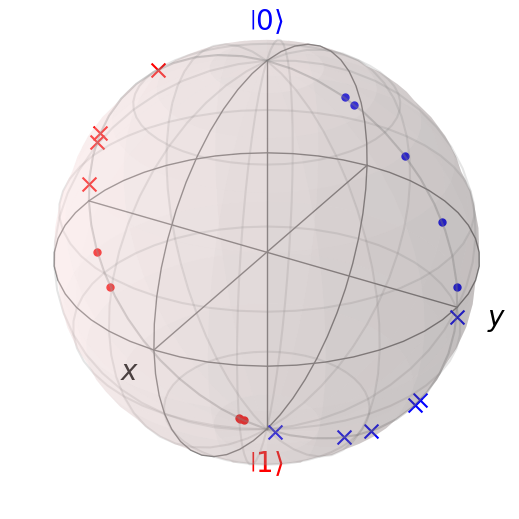

In [17]:
predict = np.argmax(probs, axis=1)
plot_bloch_visualization([statevectors0, statevectors1], x=x, x0=x0, x1=x1, score=(predict==np.array(y).reshape(predict.shape)))

The X points are those who have been misclassified.<br>
Are you surprised?<br>
How could we do better?


## Measuring along the Y-axis

To measure along the Y-axis, we proceed by applying $|\psi'\rangle = HS^\dagger|\psi\rangle$ where the $S$ gate is a $\phi = \frac{\pi}{2}$ rotation around the Z-axis.

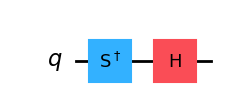

In [18]:
qc_ybasis = QuantumCircuit(1)
qc_ybasis.sdg(0)
qc_ybasis.h(0)

qc_ybasis.draw('mpl')

In [19]:
counts = get_measurement_outcomes(x, qc, qc_ybasis)
probs = get_probabilities_from_counts(counts)
accuracy = get_accuracy(probs, y)
print(f'>\n> The accuracy of our classifier is {accuracy*100}%.\n>')

>
> The accuracy of our classifier is 95.0%.
>


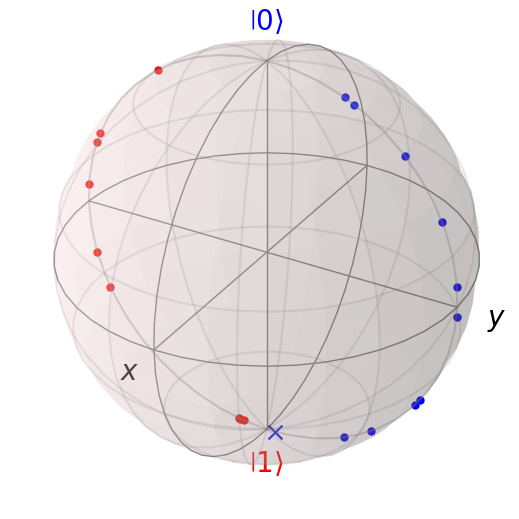

In [20]:
predict = np.argmax(probs, axis=1)
plot_bloch_visualization([statevectors0, statevectors1], x=x, x0=x0, x1=x1, score=(predict==np.array(y).reshape(predict.shape)))

# Exercise 3:
 * Implement the angle embedding such that the rotations are performed about the Y-axis.
 * Implement the quantum circuit `qc_xbasis` which performs measurements in the X basis, by simply adding a $H$ gate.<br>
 Validate your results by making sure you obtain an accuracy of 100%!

In [29]:
def angle_embedding_ry(x_params, nb_features):
    """
    Angle embedding using RY gates.

    :param x_params: List of parameters to embed.
    :param nb_features: Number of features in a data vector.

    :return: The quantum circuit applying the angle embedding.
    """

    ## Your code here!
    qc = QuantumCircuit(nb_features)
    for i in range(nb_features):
        qc.ry(x_params[i], i)

    return qc

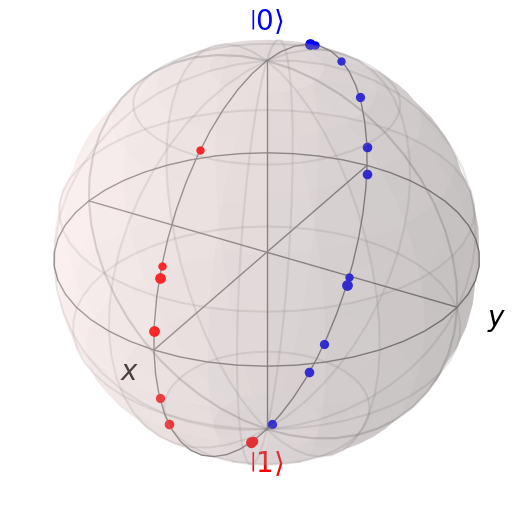

In [30]:
qc = angle_embedding_ry(x_params, 1)
statevectors0 = get_statevector(qc, x0, x_params, sv_sim)
statevectors1 = get_statevector(qc, x1, x_params, sv_sim)
plot_bloch_visualization([statevectors0, statevectors1], ['b', 'r'])

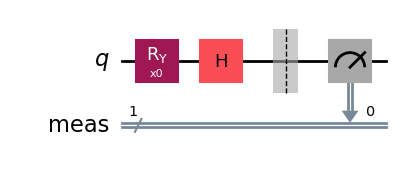

In [31]:
qc_xbasis = qc.copy()
qc_xbasis.h(0)
qc_xbasis.measure_all()

qc_xbasis.draw('mpl')

In [32]:
from qiskit_aer import Aer  # Use `from qiskit import Aer` if on Qiskit < 1.0

simulator = Aer.get_backend('qasm_simulator')
shots = 1024

# Combine class 0 and class 1 data points and labels
X_data = list(x0) + list(x1)
y_true = [0] * len(x0) + [1] * len(x1)

# Bind parameters for each data point and run on the simulator
bound_circuits = [
    qc_xbasis.assign_parameters({x_params[0]: val[0]}) for val in X_data
]

job = simulator.run(bound_circuits, shots=shots)
counts = job.result().get_counts()

# Compute probabilities and predictions
probs = [{k: v / shots for k, v in c.items()} for c in counts]
y_pred = [int(max(p, key=p.get)) for p in probs]

# Compute accuracy
accuracy = sum(p == t for p, t in zip(y_pred, y_true)) / len(y_true)

print(f'\n> The accuracy of our classifier is {accuracy*100}%.\n>')


> The accuracy of our classifier is 0.0%.
>
